Starting point to experiment with VAE


In [8]:
import sys
sys.path.append('../')

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

from src.models.vae import VAE

In [9]:
# load MNIST 
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

batch_size = 128


transform = transforms.Compose([
    transforms.ToTensor(),
])


train_data = datasets.MNIST(
    '~/.pytorch/MNIST_data/',
    download=True,
    train=True,
    transform=transform,
)


test_data = datasets.MNIST(
    '~/.pytorch/MNIST_data/',
    download=True,
    train=False,
    transform=transform,
)


train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
)

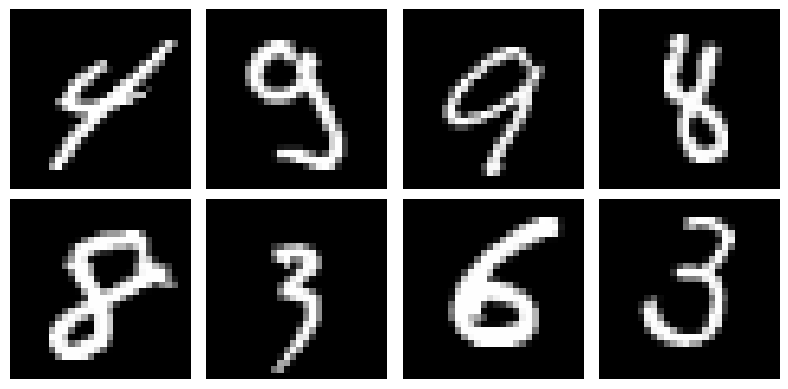

In [10]:

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')

vae = VAE().to(device)
print(f"VAE created with {sum(p.numel() for p in vae.parameters())} parameters")

images = images.to(device)

with torch.no_grad():
    output = vae(images[:8])

print(f"Total loss: {output.loss.item():.4f}")
print(f"Recon loss: {output.recon_loss.item():.4f}")
print(f"KL loss: {output.kl_loss.item():.4f}")

VAE created with 3003138 parameters
Total loss: 545.9196
Recon loss: 538.9755
KL loss: 6.9441


In [12]:
from tqdm import tqdm

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

num_epochs = 3
max_batches_per_epoch = 50
losses = {'total': [], 'recon': [], 'kl': []}

vae.train()

for epoch in range(num_epochs):
    epoch_losses = {'total': 0, 'recon': 0, 'kl': 0}
    
    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
    
    for batch_idx, (data, _) in enumerate(pbar):
        data = data.to(device)
        
        optimizer.zero_grad()
        output = vae(data)
        output.loss.backward()
        optimizer.step()
        
        epoch_losses['total'] += output.loss.item()
        epoch_losses['recon'] += output.recon_loss.item()
        epoch_losses['kl'] += output.kl_loss.item()
        
        if batch_idx >= max_batches_per_epoch:
            break
    
    num_batches = min(max_batches_per_epoch + 1, len(train_loader))
    for key in epoch_losses:
        epoch_losses[key] /= num_batches
        losses[key].append(epoch_losses[key])
    
    print(f'Epoch {epoch+1}: Total={epoch_losses["total"]:.3f}, '
          f'Recon={epoch_losses["recon"]:.3f}, KL={epoch_losses["kl"]:.3f}')

print("training completed")

Epoch 1/3:  11%|█         | 50/468 [00:19<02:40,  2.60it/s]


Epoch 1: Total=362.979, Recon=354.847, KL=8.132


Epoch 2/3:  11%|█         | 50/468 [00:16<02:21,  2.95it/s]


Epoch 2: Total=218.371, Recon=211.855, KL=6.516


Epoch 3/3:  11%|█         | 50/468 [00:18<02:34,  2.70it/s]

Epoch 3: Total=195.243, Recon=187.564, KL=7.679
training completed


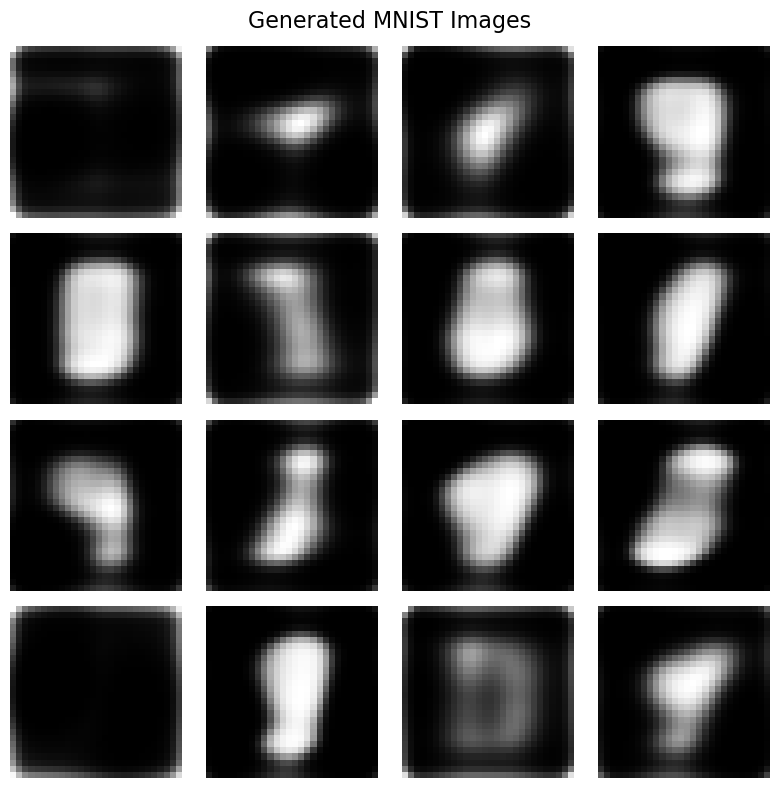

Generated 16 new images from random latent vectors!


In [13]:
import matplotlib.pyplot as plt

vae.eval()

num_samples = 16
with torch.no_grad():
    z = torch.randn(num_samples, 64, device=device)

    generated_images = vae.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle('Generated MNIST Images', fontsize=16)

for i, ax in enumerate(axes.flat):
    img = generated_images[i].cpu().squeeze()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Generated {num_samples} new images from random latent vectors!")